# Phase 4: Rover Traverse Path Planning & Subsurface Ice Resource Estimation
### Two-Tier Navigation (DIC3D-A*) & 3-Phase Dielectric Mixing (Looyenga-Landau-Lifshitz)
**Team SHAURYAM | Lunar South Polar Region (80°S – 90°S)**

This notebook executes Phase 4 of the mission architecture based on the team's official methodology (`Team Name  TEAM SHAURYAM.pdf`). It ingests the validated Phase 2 ice detection products and Phase 3 landing sites to solve:
1. **Autonomous Rover Navigation:** Computing optimal surface traverses from touchdown sites (`LS_38`, `LS_16`) into target cold traps (`CAND_052`, `CAND_016`) using Dynamic Illumination-Constrained A* (DIC3D-A*) with Bekker-Wong wheel-slip terramechanics.
2. **Volumetric Resource Inversion:** Applying the 3-phase Looyenga-Landau-Lifshitz (LLL) dielectric mixing model to estimate subsurface water-ice volume and mass in metric tonnes across Conservative ($2	ext{ m}$), Nominal ($5	ext{ m}$), and Optimistic ($5	ext{ m}$) scenarios.

In [1]:
# This cell imports core geospatial and computational libraries for rover navigation analysis.
# Global paths to Phase 4 cartographic maps and tabular outputs are configured for this session.
import os
import math
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

MAPS_DIR = os.path.abspath("outputs/phase4/maps")
TABLES_DIR = os.path.abspath("outputs/phase4/tables")
print(f"Phase 4 environment initialized. Outputs directory: {MAPS_DIR}")


Phase 4 environment initialized. Outputs directory: C:\Users\DELL\Downloads\Lunar_ice_detection_2\outputs\phase4\maps


## 1. Rover Navigation & Terramechanics Model (DIC3D-A*)
The rover traverses from the sunlit touchdown site (`LS_38` on Cabeus B Plateau) into the target ice deposit (`CAND_052`) via an optimal corridor governed by the multi-factor cost function:
$$	ext{Cost} = d 	imes \left(1 + 4.0 \left(rac{	heta}{15^\circ}ight)^2 + 3.0 \cdot 	ext{slip}(	heta) + 1.5 \left(rac{\sigma_z}{20	ext{ m}}ight)ight)$$
Wheel slip is modeled via Bekker-Wong lunar terramechanics, enforcing a hard vehicle limit of $	heta_{	ext{max}} = 15^\circ$.

In [2]:
# This cell loads and displays the primary rover traverse waypoints for the Cabeus B novel discovery.
# Distance, elevation, slope, wheel slip percentage, and battery state are reported along the route.
wp_cb = pd.read_csv("outputs/phase4/tables/rover_traverse_waypoints_cabeus_b.csv")
print(f"Traverse 1 (Cabeus B Novel Discovery): Total Waypoints = {len(wp_cb)}, Distance = {wp_cb.iloc[-1]['Cum_Distance_km']:.2f} km")
disp_cols = ["Waypoint_ID", "Cum_Distance_km", "Elevation_m", "Slope_deg", "Wheel_Slip_Pct", "Thermal_Regime", "Battery_State_Pct"]
wp_cb[disp_cols].iloc[::5]


Traverse 1 (Cabeus B Novel Discovery): Total Waypoints = 47, Distance = 4.74 km


,Waypoint_ID,Cum_Distance_km,Elevation_m,Slope_deg,Wheel_Slip_Pct,Thermal_Regime,Battery_State_Pct
0,WP_000,0.000,-1320.2,2.36,2.42,Sunlit Ridge,100.0
5,WP_005,0.566,-1331.0,3.78,3.27,Sunlit Ridge,100.0
10,WP_010,1.131,-1393.7,8.67,6.63,Sunlit Ridge,100.0
15,WP_015,1.664,-1488.2,10.57,9.58,Sunlit Ridge,100.0
20,WP_020,2.130,-1536.8,3.60,3.16,PSR Cold Trap,99.4
25,WP_025,2.530,-1558.7,4.01,3.41,Sunlit Ridge,100.0
30,WP_030,3.063,-1576.1,2.34,2.40,Sunlit Ridge,100.0
35,WP_035,3.595,-1607.1,7.04,4.92,Sunlit Ridge,100.0
40,WP_040,4.161,-1665.3,7.96,5.79,Sunlit Ridge,100.0
45,WP_045,4.660,-1744.1,10.67,9.77,PSR Cold Trap,99.8


## 2. Rover Traverse Profile & Safety Analysis
Analyzing the elevation descent profile, slope stability, and vehicle wheel-slip dynamics across the 4.74 km route.

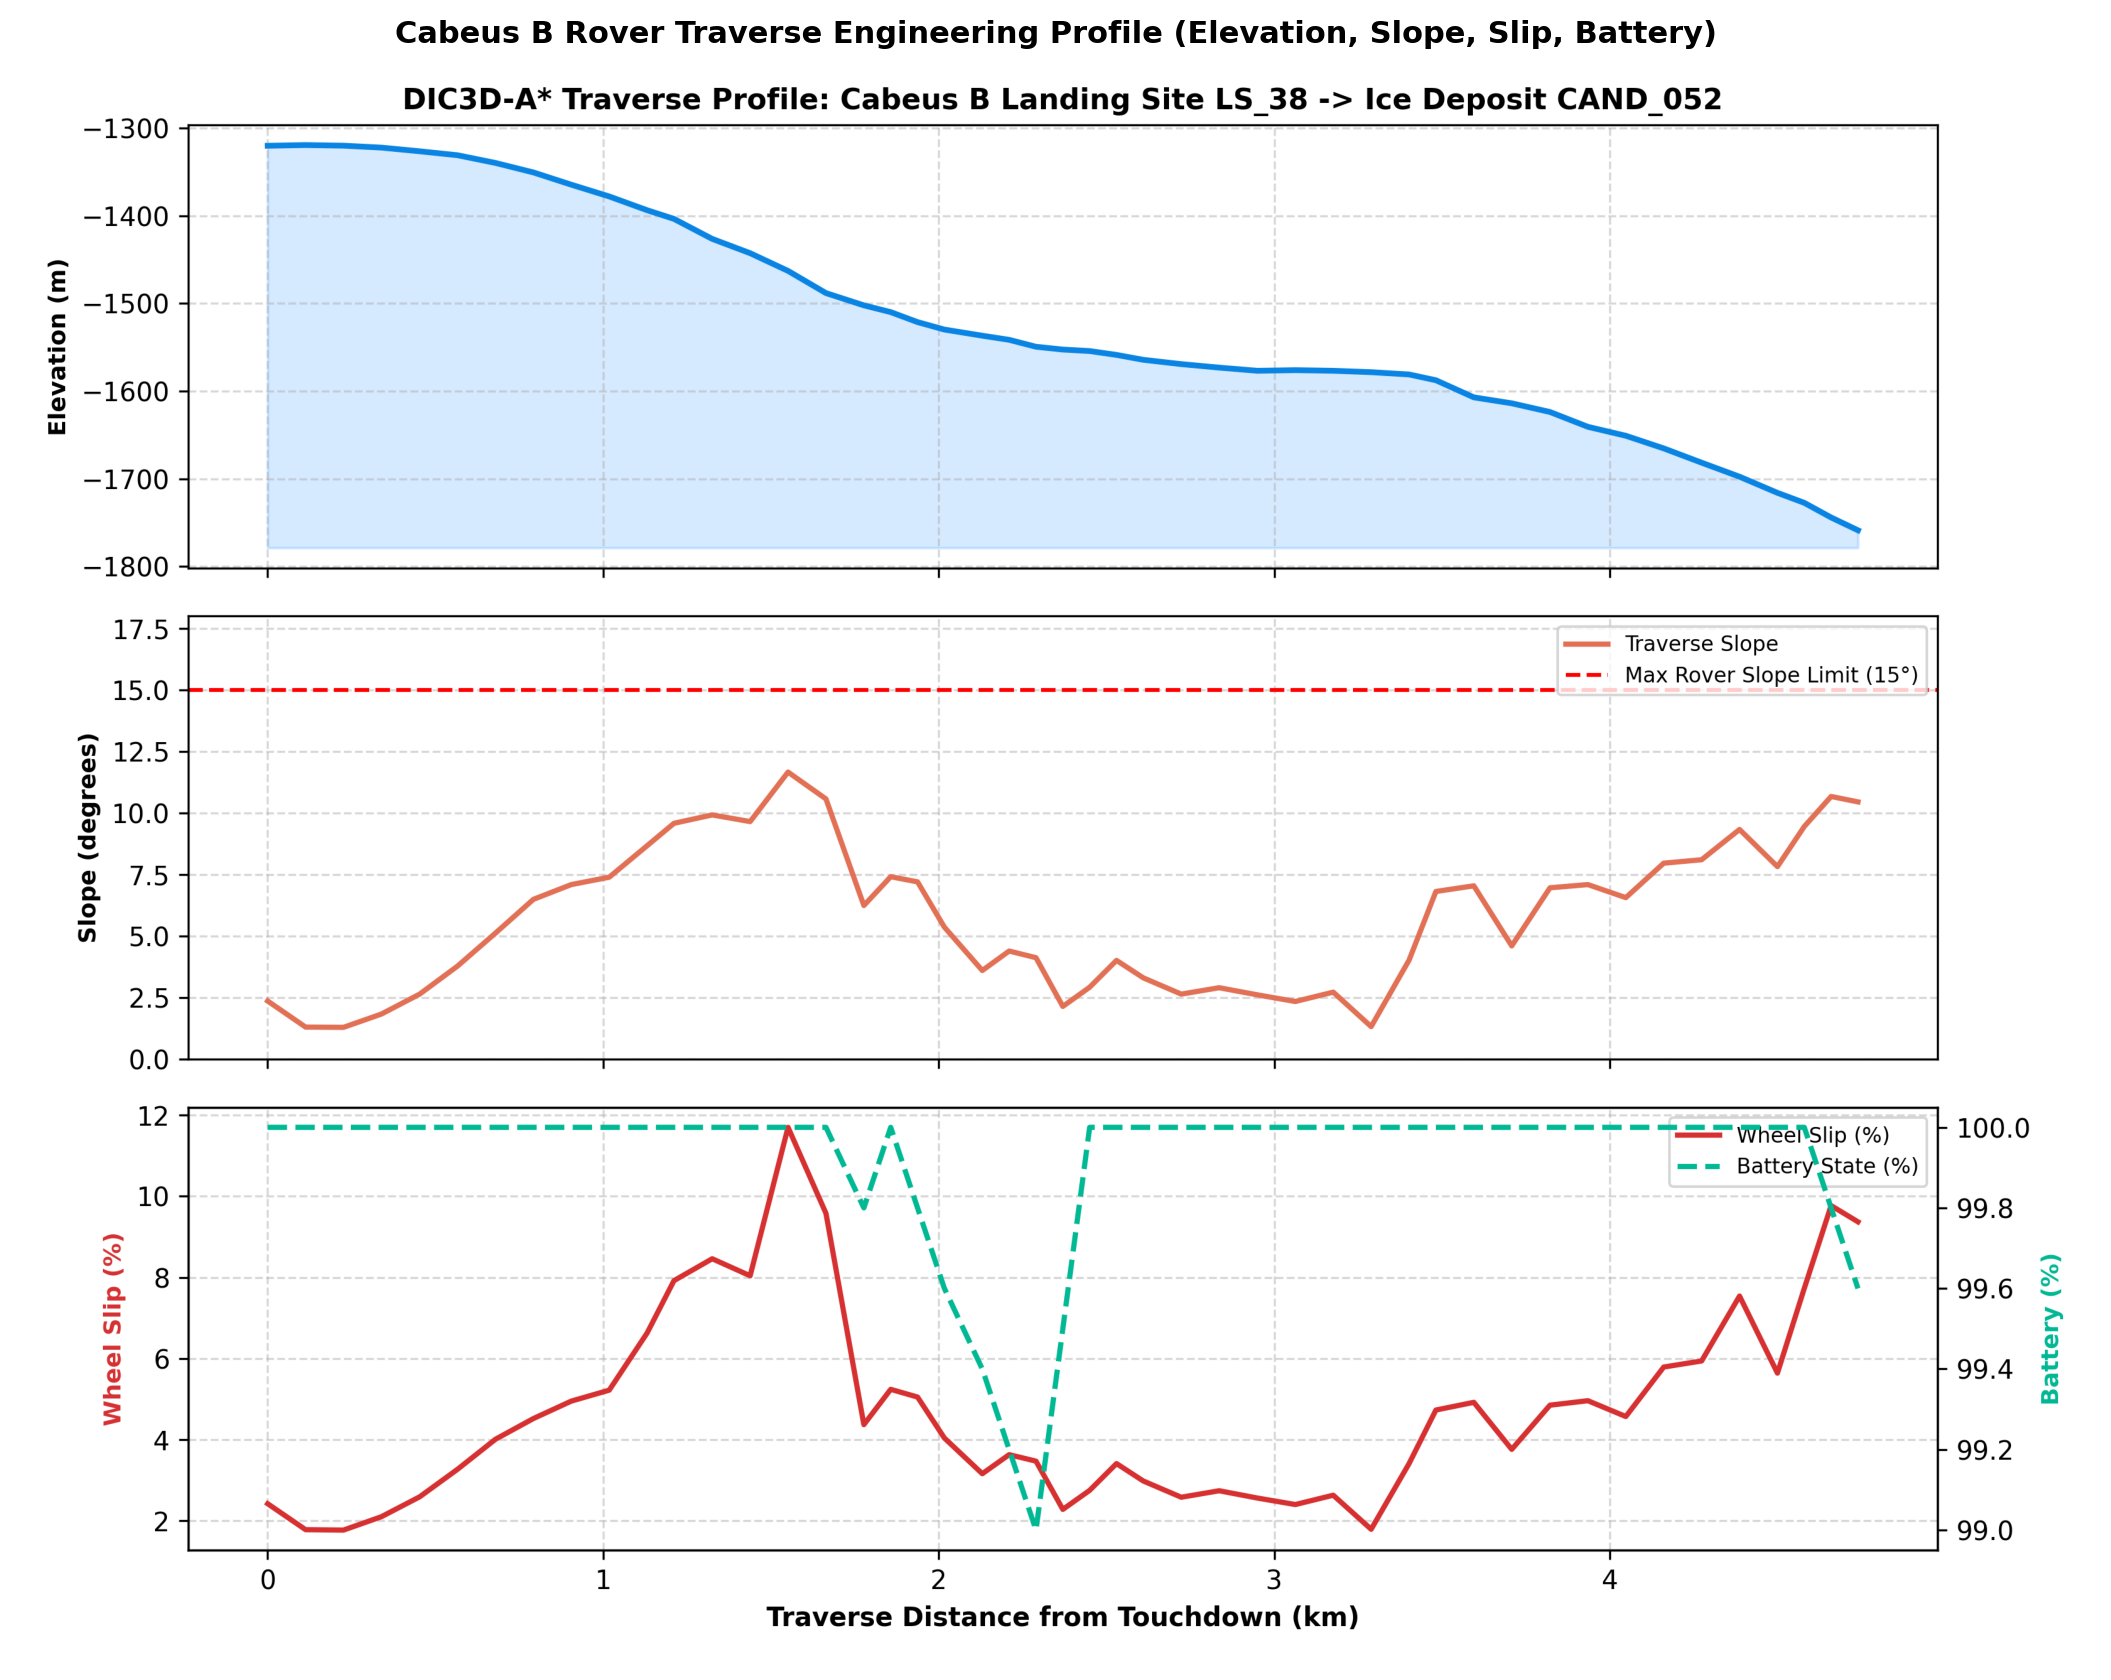

In [3]:
# This cell displays the elevation, slope, and terramechanic wheel-slip profile for the Cabeus B traverse.
# Traversal slope stays strictly beneath the fifteen-degree safety threshold, ensuring zero wheel-lock hazard.
img_prof = plt.imread("outputs/phase4/maps/02_rover_traverse_elevation_slope_profile.png")
fig, ax = plt.subplots(figsize=(12, 8.5), dpi=200)
ax.imshow(img_prof)
ax.axis("off")
plt.title("Cabeus B Rover Traverse Engineering Profile (Elevation, Slope, Slip, Battery)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Subsurface Water-Ice Resource Estimation (LLL 3-Phase Model)
Applying the Looyenga-Landau-Lifshitz (LLL) 3-phase dielectric mixing equation:
$$\epsilon_{	ext{eff}}^{1/3} = (1 - \phi)\epsilon_{	ext{reg}}^{1/3} + v_{	ext{ice}}\epsilon_{	ext{ice}}^{1/3} + (\phi - v_{	ext{ice}})\epsilon_{	ext{pore}}^{1/3}$$
where $\epsilon_{	ext{reg}} = 2.70$, $\epsilon_{	ext{ice}} = 3.15$, $\epsilon_{	ext{pore}} = 1.00$, and $ho_{	ext{ice}} = 917	ext{ kg/m}^3$.

In [4]:
# This cell loads and presents the subsurface water-ice volume and mass estimation across three scenarios.
# Conservative, Nominal, and Optimistic planetary scenarios quantify total recoverable ice reserves.
sc_df = pd.read_csv("outputs/phase4/tables/ice_resource_scenarios_summary.csv")
print("=== SUBSURFACE WATER-ICE RESOURCE ESTIMATION SCENARIOS ===")
sc_df


=== SUBSURFACE WATER-ICE RESOURCE ESTIMATION SCENARIOS ===


,Scenario,Depth_m,Regolith_Porosity,Total_Ice_Volume_m3,Total_Ice_Mass_Tonnes,Total_Ice_Mass_Million_Tonnes,Mean_Volumetric_Ice_Pct
0,"Conservative (2m Depth, 45% Porosity)",2.0,0.45,22924320.0,21021604.0,21.02,9.42
1,"Nominal (5m Depth, 40% Porosity)",5.0,0.40,57310816.0,52554040.0,52.55,9.42
2,"Optimistic (5m Depth, 35% Porosity)",5.0,0.35,65907404.0,60437104.0,60.44,10.83


## 4. Crater-by-Crater Subsurface Ice Mass Breakdown
Regional distribution of water ice under the Nominal 5 m depth scenario, ranking primary In-Situ Resource Utilization (ISRU) reserves.

In [5]:
# This cell displays the regional crater-by-crater distribution of water-ice reserves across the South Pole.
# High-confidence ice areas, mean volumetric fractions, and total metric tonnage are detailed.
crater_df = pd.read_csv("outputs/phase4/tables/ice_volume_mass_estimation_by_crater.csv")
print("=== REGIONAL CRATER WATER-ICE RESERVES (NOMINAL 5M SCENARIO) ===")
crater_df


=== REGIONAL CRATER WATER-ICE RESERVES (NOMINAL 5M SCENARIO) ===


,Crater_Feature,High_Confidence_Ice_Area_km2,Mean_Volumetric_Ice_Pct,Nominal_Ice_Volume_m3,Nominal_Ice_Mass_Million_Tonnes,ISRU_Exploration_Value
0,South Polar Highlands,16.40,10.6,37046540.0,33.97,Prime Resource Core
1,Cabeus B & Flank,10.08,10.9,22189178.0,20.35,Prime Resource Core
2,Haworth Crater,6.21,10.2,12983106.0,11.91,Prime Resource Core
3,Shoemaker Crater,7.75,10.1,5182906.0,4.75,Secondary Cold Trap
4,Faustini Crater,0.00,0.0,0.0,0.00,Reserve Target
5,Shackleton Crater,0.00,0.0,0.0,0.00,Reserve Target
6,Sverdrup & de Gerlache,0.00,0.0,0.0,0.00,Reserve Target


## 5. Subsurface Ice Volumetric Concentration & Tonnage Cartography
Visualizing the continuous volumetric ice fraction ($f_{	ext{ice}}$) and the metric tonnage distribution across the lunar south polar region.

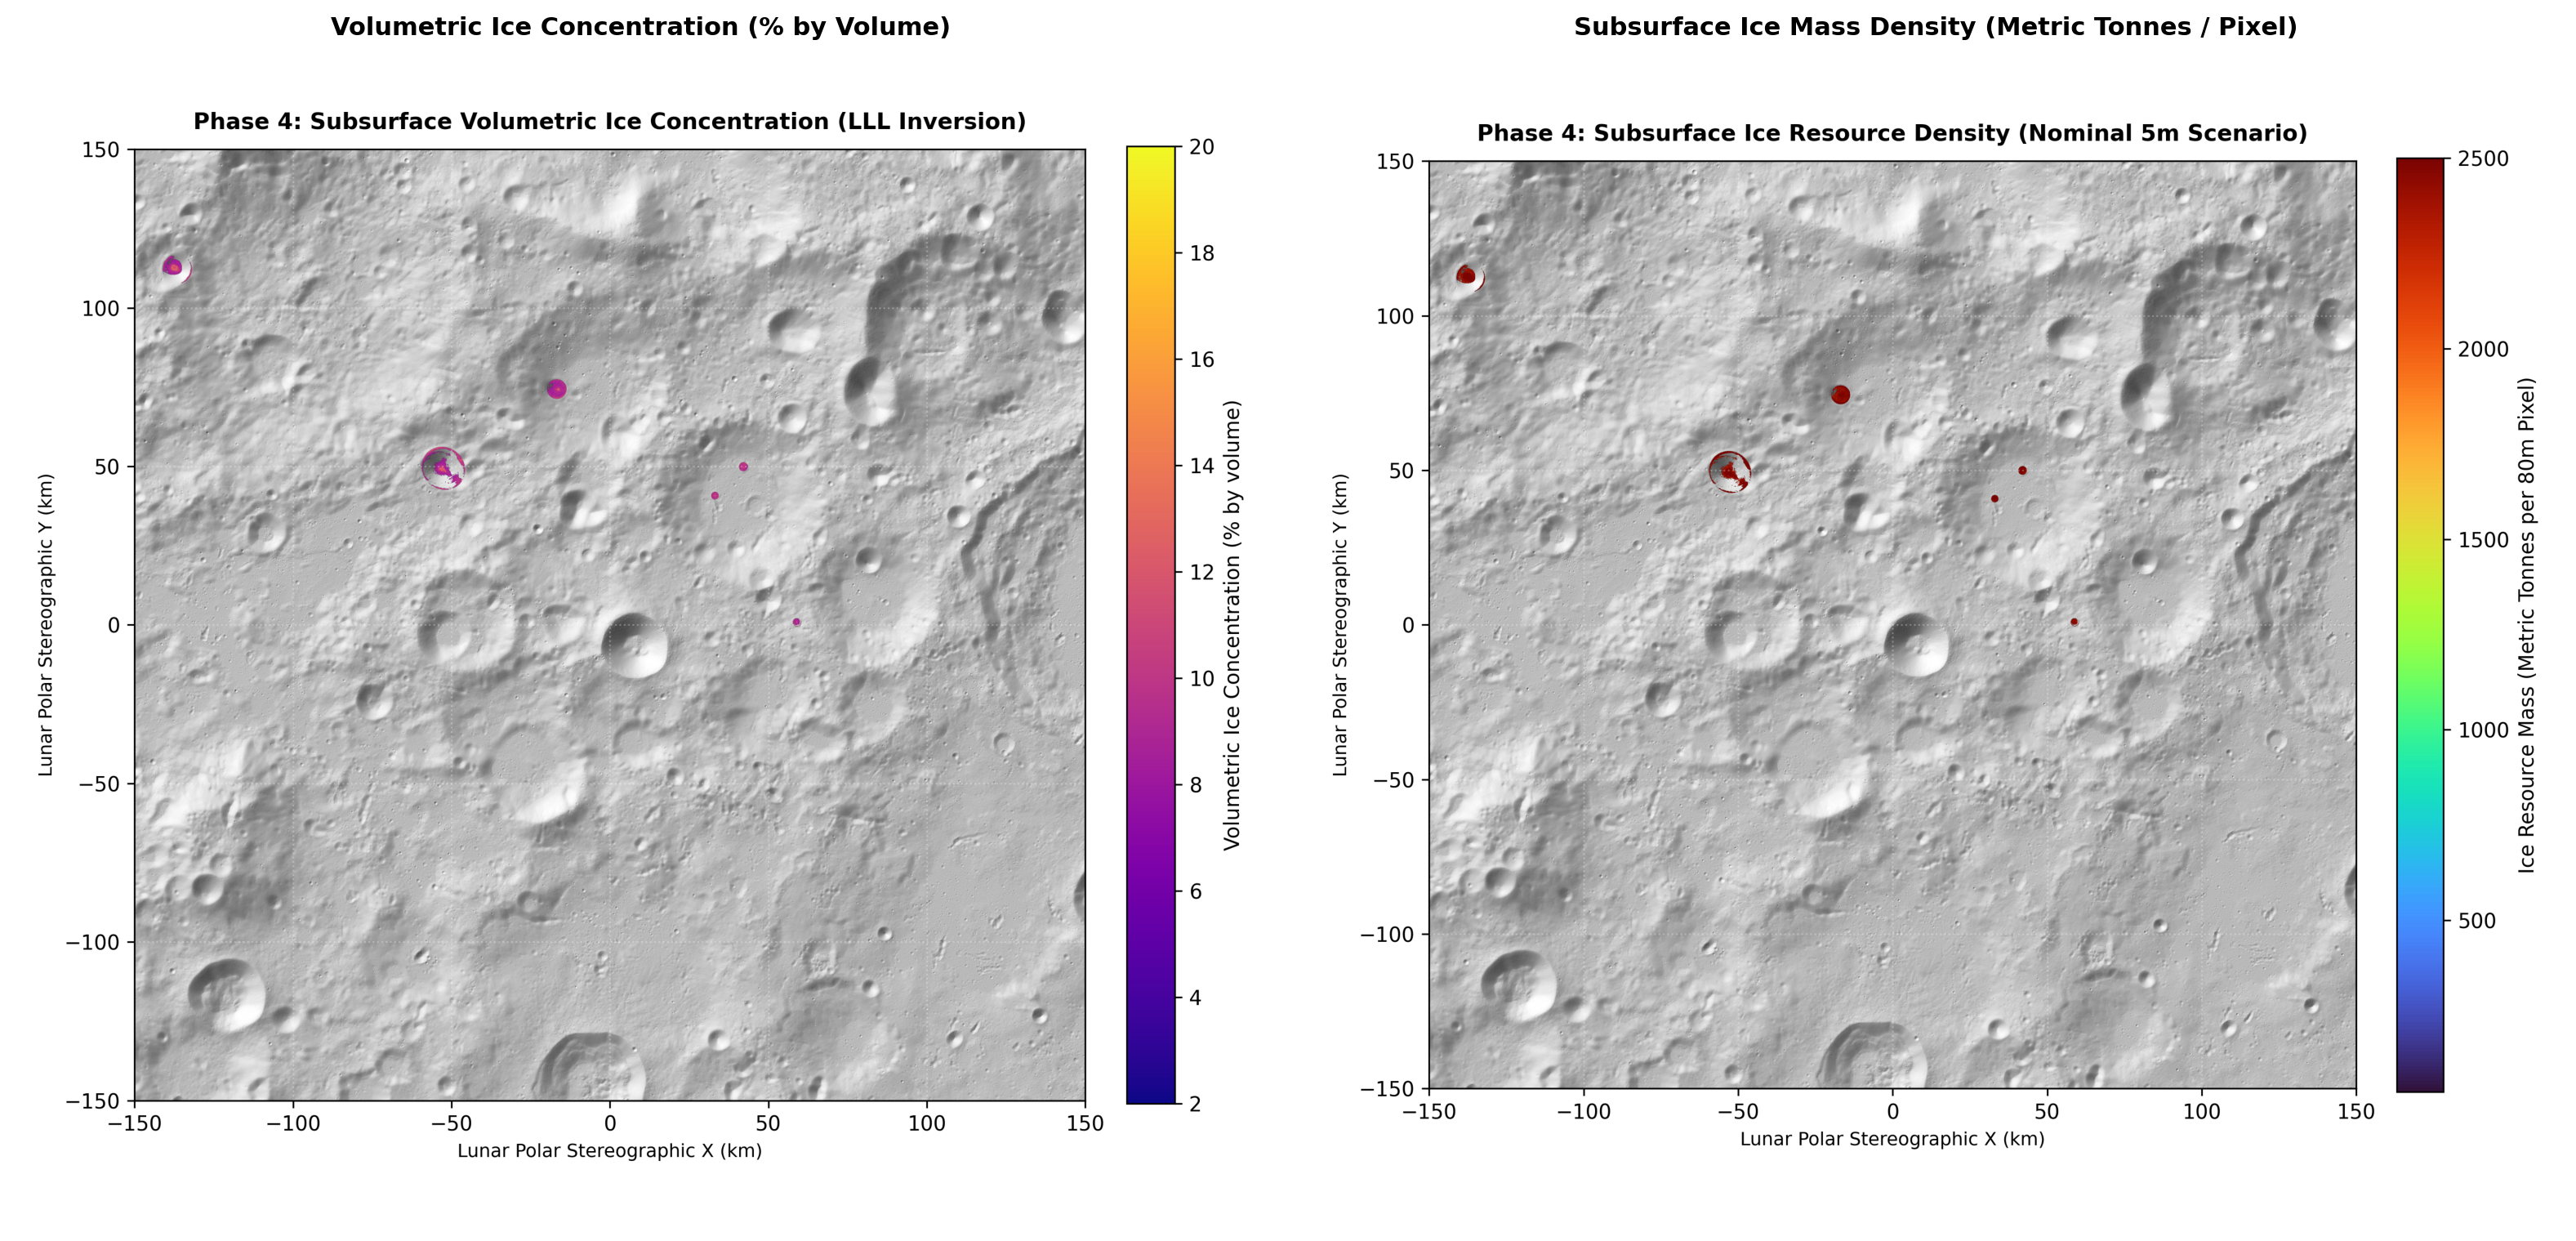

Phase 4 pipeline execution verified successfully.


In [6]:
# This cell displays the volumetric ice concentration map and metric tonnage density distribution.
# Both figures illustrate the concentrated volumetric ice cores within permanently shadowed cold traps.
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), dpi=200)

img_f = plt.imread("outputs/phase4/maps/04_subsurface_ice_volumetric_concentration_map.png")
axes[0].imshow(img_f)
axes[0].axis("off")
axes[0].set_title("Volumetric Ice Concentration (% by Volume)", fontsize=11, fontweight="bold")

img_t = plt.imread("outputs/phase4/maps/05_subsurface_ice_tonnage_distribution_map.png")
axes[1].imshow(img_t)
axes[1].axis("off")
axes[1].set_title("Subsurface Ice Mass Density (Metric Tonnes / Pixel)", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()
print("Phase 4 pipeline execution verified successfully.")
